In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/yield_df.csv')

In [5]:
sa_maize = df[(df['Area']=='South Africa') & (df['Item']=='Maize')]

In [6]:
print(sa_maize.head())
print(sa_maize.info())
print(sa_maize.isnull().sum())

       Unnamed: 0          Area   Item  Year  hg/ha_yield  \
24555       24555  South Africa  Maize  1990        22051   
24556       24556  South Africa  Maize  1990        22051   
24557       24557  South Africa  Maize  1990        22051   
24558       24558  South Africa  Maize  1990        22051   
24583       24583  South Africa  Maize  1991        22573   

       average_rain_fall_mm_per_year  pesticides_tonnes  avg_temp  
24555                          495.0            16582.0     20.56  
24556                          495.0            16582.0     15.56  
24557                          495.0            16582.0     18.91  
24558                          495.0            16582.0     15.56  
24583                          495.0            16582.0     21.06  
<class 'pandas.core.frame.DataFrame'>
Index: 92 entries, 24555 to 25174
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 

In [7]:
sa_maize = sa_maize.dropna()

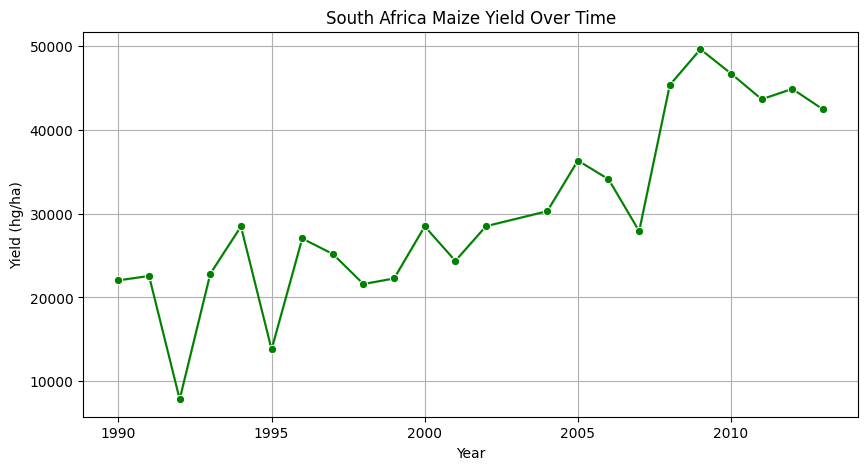

In [12]:
# Sort data by Year so the line connects chronologically
sa_maize = sa_maize.sort_values('Year')

plt.figure(figsize=(10, 5))
sns.lineplot(data=sa_maize, x='Year', y='hg/ha_yield', marker='o', color='green')

plt.title('South Africa Maize Yield Over Time')
plt.xlabel('Year')
plt.ylabel('Yield (hg/ha)')
plt.grid(True)
plt.show()

/tmp/ipykernel_528/787749101.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=sadc_maize, x='Area', y='hg/ha_yield', palette='viridis', errorbar=None)


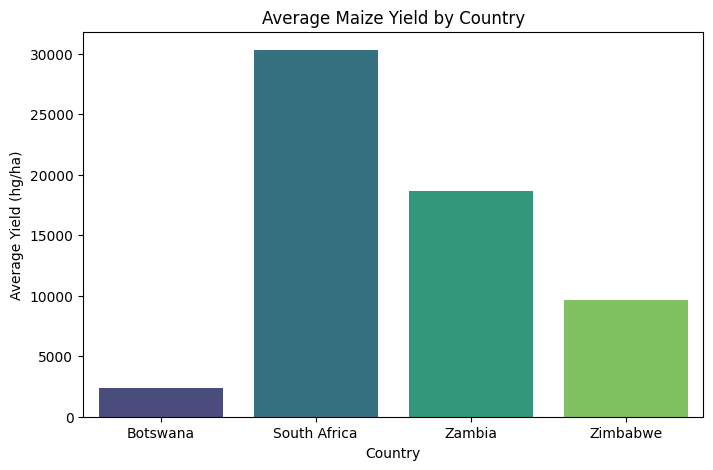

In [13]:
# Example: Comparing average yield across Southern African countries
sadc_maize = df[(df['Area'].isin(['South Africa', 'Zimbabwe', 'Zambia', 'Botswana'])) & (df['Item'] == 'Maize')]

plt.figure(figsize=(8, 5))
sns.barplot(data=sadc_maize, x='Area', y='hg/ha_yield', palette='viridis', errorbar=None)

plt.title('Average Maize Yield by Country')
plt.xlabel('Country')
plt.ylabel('Average Yield (hg/ha)')
plt.show()

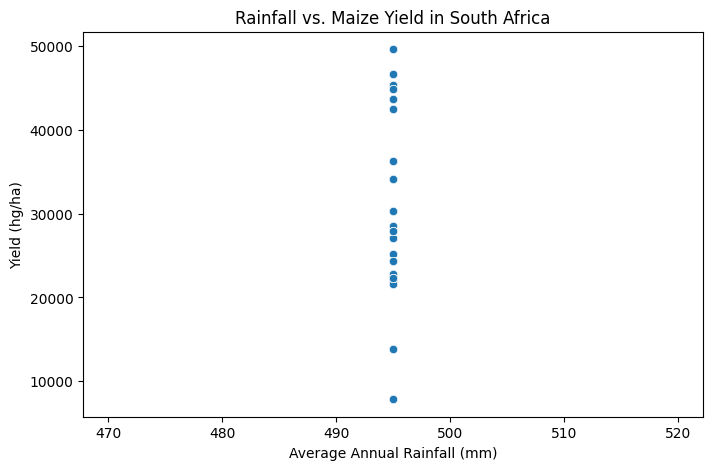

In [14]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=sa_maize, x='average_rain_fall_mm_per_year', y='hg/ha_yield')

plt.title('Rainfall vs. Maize Yield in South Africa')
plt.xlabel('Average Annual Rainfall (mm)')
plt.ylabel('Yield (hg/ha)')
plt.show()

In [17]:
from sklearn.model_selection import train_test_split

X = sa_maize[['average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp']]
y =sa_maize['hg/ha_yield']
# Keep 80% for training and hide 20% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [18]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# 1. Baseline Model: Linear Regression
baseline_model = LinearRegression()
baseline_model.fit(X_train, y_train)

# 2. Recommended Model: Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [19]:
from sklearn.metrics import mean_absolute_error, r2_score

# Make predictions on the test data
rf_preds = rf_model.predict(X_test)

# Calculate error and accuracy score
mae = mean_absolute_error(y_test, rf_preds)
r2 = r2_score(y_test, rf_preds)

print(f"Mean Absolute Error: {mae:.2f}")
print(f"R2 Score: {r2:.2f}")

Mean Absolute Error: 6053.84
R2 Score: 0.37


In [20]:
# Use the full dataset (or all Maize rows globally) instead of just 30 SA rows
maize_df = df[df['Item'] == 'Maize'].dropna()

X = pd.get_dummies(maize_df[['Area', 'Year', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp']], drop_first=True)
y = maize_df['hg/ha_yield']

In [21]:
# Use the full dataset (or all Maize rows globally) instead of just 30 SA rows
maize_df = df[df['Item'] == 'Maize'].dropna()

X = pd.get_dummies(maize_df[['Area', 'Year', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp']], drop_first=True)
y = maize_df['hg/ha_yield']

In [22]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(rf_model, X, y, cv=5, scoring='r2')
print("Average R2 across 5 splits:", scores.mean())

Average R2 across 5 splits: 0.11040568649221472


In [23]:
from sklearn.model_selection import KFold, cross_val_score

kf = KFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(rf_model, X, y, cv=kf, scoring='r2')

print("Shuffled R2 across 5 splits:", scores.mean())

Shuffled R2 across 5 splits: 0.9663801811642558


In [24]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

preds = rf_model.predict(X_test)
print("Overall Test R2:", r2_score(y_test, preds))
print("Overall Test MAE:", mean_absolute_error(y_test, preds))

Overall Test R2: 0.9640650017236807
Overall Test MAE: 2351.7477090909088


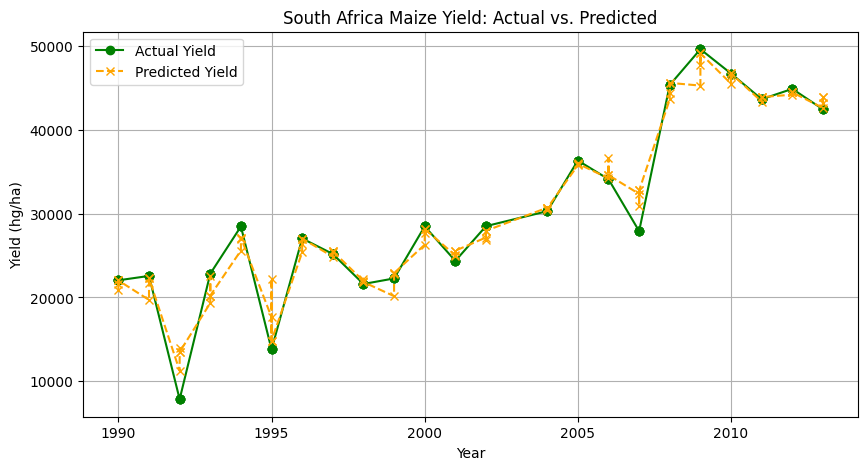

In [25]:
# Filter the original maize dataframe for South Africa
sa_only = maize_df[maize_df['Area'] == 'South Africa'].copy()

# Prepare features using the exact same columns as X_train
sa_features = pd.get_dummies(maize_df[['Area', 'Year', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp']], drop_first=True)
sa_X = sa_features.loc[sa_only.index]

# Predict using your trained model
sa_only['Predicted_Yield'] = rf_model.predict(sa_X)

# Plot Actual vs. Predicted Yield for South Africa
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(sa_only['Year'], sa_only['hg/ha_yield'], label='Actual Yield', marker='o', color='green')
plt.plot(sa_only['Year'], sa_only['Predicted_Yield'], label='Predicted Yield', linestyle='--', marker='x', color='orange')
plt.title('South Africa Maize Yield: Actual vs. Predicted')
plt.xlabel('Year')
plt.ylabel('Yield (hg/ha)')
plt.legend()
plt.grid(True)
plt.show()

/tmp/ipykernel_528/2176904764.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_10.values, y=top_10.index, palette='magma')


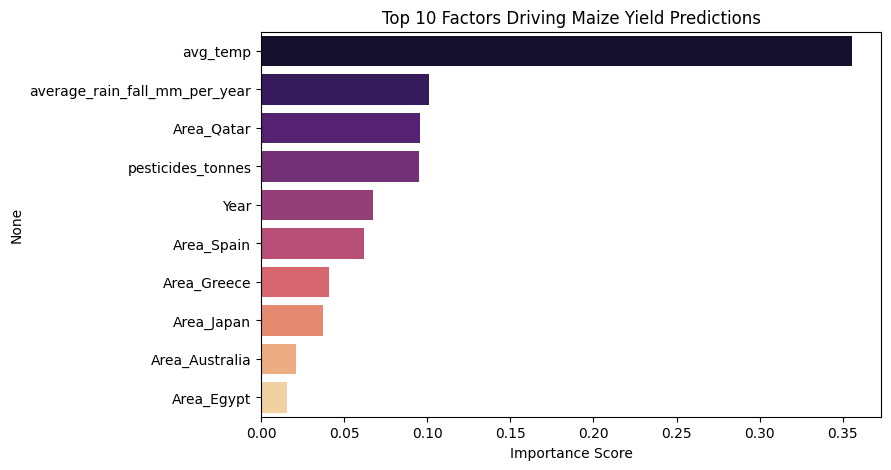

In [26]:
import pandas as pd
import seaborn as sns

# Extract top 10 most important features
importances = pd.Series(rf_model.feature_importances_, index=X.columns)
top_10 = importances.nlargest(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=top_10.values, y=top_10.index, palette='magma')
plt.title('Top 10 Factors Driving Maize Yield Predictions')
plt.xlabel('Importance Score')
plt.show()

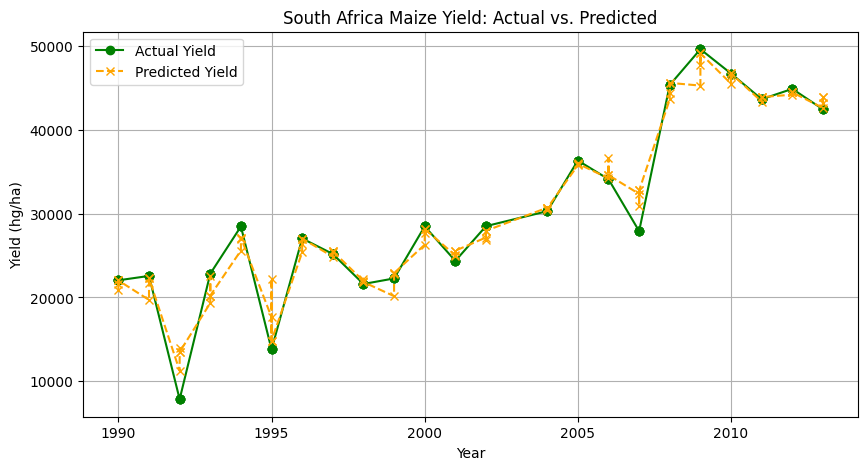

In [27]:
plt.figure(figsize=(10, 5))
plt.plot(sa_only['Year'], sa_only['hg/ha_yield'], label='Actual Yield', marker='o', color='green')
plt.plot(sa_only['Year'], sa_only['Predicted_Yield'], label='Predicted Yield', linestyle='--', marker='x', color='orange')
plt.title('South Africa Maize Yield: Actual vs. Predicted')
plt.xlabel('Year')
plt.ylabel('Yield (hg/ha)')
plt.legend()
plt.grid(True)

# Save the chart before displaying it
plt.savefig('sa_maize_prediction.png', dpi=300, bbox_inches='tight')
plt.show()

In [28]:
import joblib

# Save the trained Random Forest model
joblib.dump(rf_model, 'maize_yield_model.joblib')

# Save the exact list of column names used during training
joblib.dump(list(X.columns), 'model_columns.joblib')

print("Model and columns saved successfully.")

Model and columns saved successfully.


In [29]:
from google.colab import files

files.download('sa_maize_prediction.png')
files.download('maize_yield_model.joblib')
files.download('model_columns.joblib')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>